<a href="https://colab.research.google.com/github/michael-zhang0/L02-hedonic-pricing/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sihan Michael Zhang, Samuel Bromberg, Sam Nieto Beltran

**Date:** 11/9/2026

In [2]:
!git clone https://github.com/michael-zhang0/L02-hedonic-pricing.git
%cd L02-hedonic-pricing

Cloning into 'L02-hedonic-pricing'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 9 (delta 0), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 248.75 KiB | 3.11 MiB/s, done.
/content/L02-hedonic-pricing/L02-hedonic-pricing


(16814, 19)
    sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
0  2020-01-02      380000               2157                           0   
1  2020-01-02      383000               2238                           0   
2  2020-01-01      419900               1452                           0   
3  2020-01-02      251660                832                           0   
4  2020-01-02      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces        hvac_description  \
0                            0           0  Warm and Cool Air Zone   
1                            0           0            

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64
0
waterfront_type
NaN                16261
WF Lake              225
WF Salt              209
WF Stream/Creek       93
WF River              26
Name: count, dtype: int64
view_quality
NaN            15895
View Lim         229
View Lim -       214
View Avg         152
View Lim +       1

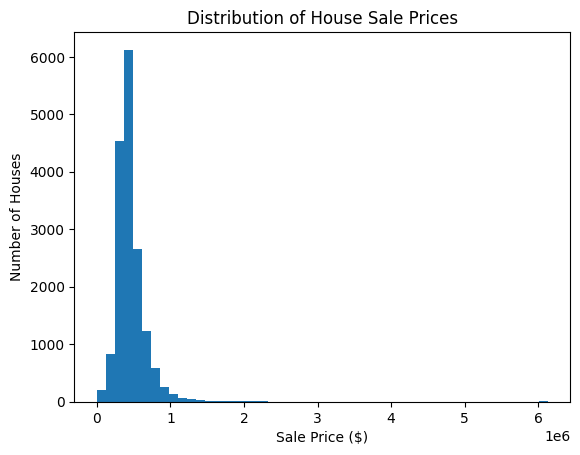

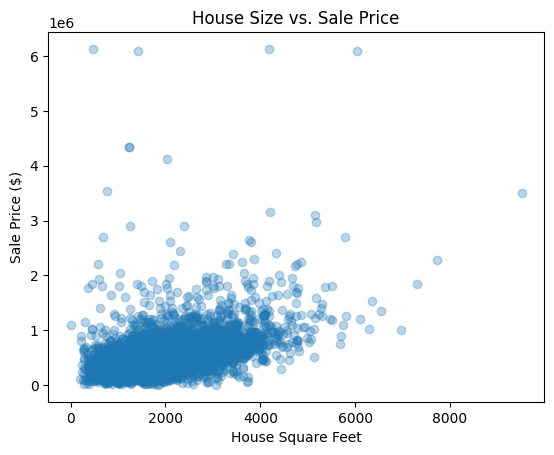

sale_price                     1.000000
house_square_feet              0.526326
bathrooms                      0.409438
fireplaces                     0.348467
attached_garage_square_feet    0.310756
basement_square_feet           0.269653
year_built                     0.228881
bedrooms                       0.205495
stories                        0.166519
detached_garage_square_feet    0.051764
attic_finished_square_feet     0.021566
Name: sale_price, dtype: float64


In [12]:
# Q1
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/pierce_county_house_sales.csv")

print(df.shape)
print(df.head())
df.info()
display(df.describe())
print(df.isnull().sum())

# Copy original dataset
df_clean = df.copy()

# Convert date column
df_clean["sale_date"] = pd.to_datetime(
    df_clean["sale_date"], errors="coerce"
)

print(df_clean["sale_date"].isna().sum())

# Fill missing categorical values
cols = ["hvac_description", "exterior", "interior", "roof_cover"]

df_clean[cols] = df_clean[cols].fillna("Unknown")

print(df["waterfront_type"].value_counts(dropna=False))
print(df["view_quality"].value_counts(dropna=False))

df_clean["waterfront_type"] = df_clean["waterfront_type"].fillna("Unknown")
df_clean["view_quality"] = df_clean["view_quality"].fillna("Unknown")

print("Houses with 0 stories:",
      (df_clean["stories"] == 0).sum())
print("Houses under 300 sqft:",
      (df_clean["house_square_feet"] < 300).sum())
print("Sales under $40000:",
      (df_clean["sale_price"] <= 50000).sum())

print(df_clean.isnull().sum())

plt.hist(df_clean["sale_price"], bins=50)
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Sale Prices")
plt.show()

plt.scatter(
    df_clean["house_square_feet"],
    df_clean["sale_price"],
    alpha=0.3
)
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price ($)")
plt.title("House Size vs. Sale Price")
plt.show()

correlations = df_clean.corr(numeric_only=True)["sale_price"]
print(correlations.sort_values(ascending=False))

The dataset has 16814 sales and 19 variables. Sale dates were converted to datetime and missing categorical values were replaced with "Unknown" to preserve observations. There are no missing values left after cleaning.

The distribution of sales prices is heavily right-skewed, with a mean of $461223 and median of $416500. The scatter plot shows a positive relationship between house price and sale price, though there is a lot of variation between similar sized houses.

The correlation analysis showed that house square footage has the strongest correlation with price at 0.526, then bathrooms at 0.409, then fireplaces at 0.348 and attached garage square footage at 0.311. It is interesting that bathrooms have almost twice as much correlation as bedrooms at 0.205. Overall, this suggests that the size of housing and amenities are some of the most important factors in predicting housing prices.

There is also 36 houses with zero recorded stories, 16 houses under 300 square feet, and 45 sales below $40,000. These are unusual observations but are kept for now.

In [13]:
# Q2

# Get categorical features
categorical_cols = df_clean.select_dtypes(include="object").columns

print(categorical_cols.tolist())

# One-hot encode categorical columns
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True, dtype=int)

print(df_encoded.shape)
df_encoded.head()

# Transform date
df_encoded["sale_year"] = df_encoded["sale_date"].dt.year
df_encoded["sale_month"] = df_encoded["sale_date"].dt.month

df_encoded = df_encoded.drop(columns=["sale_date"])

# Separate features and target "sale_price"
X = df_encoded.drop(columns=["sale_price"])
y = df_encoded["sale_price"]

print("Predictor matrix:", X.shape)
print("Target:", y.shape)

print("Missing values:", X.isnull().sum().sum())
print("Non-numeric columns:", X.select_dtypes(exclude="number").columns.tolist())

['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
(16814, 61)
Predictor matrix: (16814, 61)
Target: (16814,)
Missing values: 0
Non-numeric columns: []


In [15]:
# Q3
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (13451, 61)
X_test: (3363, 61)
y_train: (13451,)
y_test: (3363,)


In [16]:

# Q4
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Different sets of predictors
models = {"Square Footage": ["house_square_feet"],
          "Size + Bathrooms": ["house_square_feet", "bathrooms"],
          "Size + Bathrooms + Fireplaces": ["house_square_feet", "bathrooms", "fireplaces"],
          "All Features": X_train.columns.tolist()}

results = []

for name, features in models.items():
    model = LinearRegression()
    model.fit(X_train[features], y_train)

    train_pred = model.predict(X_train[features])
    test_pred = model.predict(X_test[features])

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    results.append({"Model": name, "Train RMSE": train_rmse, "Test RMSE": test_rmse,
                    "Train R2": train_r2, "Test R2": test_r2})

results_df = pd.DataFrame(results)
display(results_df.sort_values("Test RMSE"))


,Model,Train RMSE,Test RMSE,Train R2,Test R2
3,All Features,159305.206785,150847.117096,0.549810,0.571732
2,Size + Bathrooms + Fireplaces,200370.402384,192308.942174,0.287798,0.303950
1,Size + Bathrooms,201994.469057,195098.494546,0.276205,0.283611
0,Square Footage,202048.913005,195380.100845,0.275815,0.281541


Four linear models were made with more features in each one and their performance was evaluated using RMSE and R² on both the training and testing datasets.

The model using only square footage achieved a test RMSE of approximately $195380 and a test R² of 0.282. Adding bathrooms produced only a small improvement, while including fireplaces increased the test R² to 0.304.

The model using all available features performed significantly better, achieving a training RMSE of $159305, a testing RMSE of $150847, and a testing R² of 0.572. This is roughly a 22.8% reduction in test RMSE compared to the square footage-only model.

The All Features model also showed no obvious signs of overfitting, as its training and testing performance were relatively similar. Overall, including more features improved the model's ability to predict housing prices greatly.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]